# STI 2026 camera-ready experiments (Kaggle)
Accelerator: **GPU T4 x2 (use one)**, Internet **On**. Add the two raw CSVs as Input datasets.
Sections: 0 setup, 1 data and split, 2 LightGBM, 3 Transformer runs (GPU, resumable), 4 analysis on saved probabilities, 5 near-duplicates, 6 source checks.
Run section 3 once; every run saves its probabilities and is skipped if the files already exist (so a restarted session resumes). Click **Save Version** so `/kaggle/working` is kept.

In [1]:
%pip -q install datasketch

Note: you may need to restart the kernel to use updated packages.


In [2]:
## 1. Data and canonical split (same code and seed as the paper)import os, re, json, gc, time, math, random
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

OUT = "/kaggle/working"
# >>> EDIT these two paths (Add Input panel -> copy path)
V14_PATH = "/kaggle/input/datasets/nabilaferdous/suicidevsdepressiondetection/Suicide_Detection.csv"
V13_PATH = "/kaggle/input/datasets/nabilaferdous/suicidevsdepressiondetection/SuicideAndDepression_Detection.csv"
# Optional: if you uploaded your ORIGINAL train/val/test CSVs, point to that folder instead (text,label columns)
SPLIT_DIR = None

if SPLIT_DIR:
    train_df = pd.read_csv(f"{SPLIT_DIR}/train_split.csv"); val_df = pd.read_csv(f"{SPLIT_DIR}/val_split.csv"); test_df = pd.read_csv(f"{SPLIT_DIR}/test_split.csv")
else:
    v14 = pd.read_csv(V14_PATH)[['text','class']]; v14['source'] = 'v14_Suicide_Detection'
    v13 = pd.read_csv(V13_PATH)[['text','class']]; v13['source'] = 'v13_SuicideAndDepression'
    for d in (v14, v13): d['class'] = d['class'].str.lower().str.strip()
    v14['final_label'] = v14['class'].map({'suicide':'Suicide','non-suicide':'Teenagers'})
    v13['final_label'] = v13['class'].map({'suicidewatch':'Suicide','depression':'Depression','teenagers':'Teenagers'})
    print("raw rows:", len(v14), len(v13))
    df = pd.concat([v14, v13], ignore_index=True)
    df.drop_duplicates(subset=['text'], inplace=True)          # keeps the FIRST copy (v14 wins ties)
    df.dropna(subset=['final_label','text'], inplace=True)
    df['label'] = df['final_label'].map({'Teenagers':0,'Depression':1,'Suicide':2})
    df = df[['text','label','source']].reset_index(drop=True)
    print("\nUnique posts surviving exact dedup, by source file x label:")
    print(pd.crosstab(df['source'], df['label']))
    train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

print("split sizes:", len(train_df), len(val_df), len(test_df), "(paper: 243676 / 52216 / 52217)")
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
np.save(f"{OUT}/y_val.npy", y_val); np.save(f"{OUT}/y_test.npy", y_test)
test_df.to_csv(f"{OUT}/test_split_with_source.csv", index=False)

raw rows: 232074 348124

Unique posts surviving exact dedup, by source file x label:
label                          0       1       2
source                                          
v13_SuicideAndDepression       0  116035       0
v14_Suicide_Detection     116037       0  116037
split sizes: 243676 52216 52217 (paper: 243676 / 52216 / 52217)


## 2. LightGBM stream (TF-IDF). Deterministic (no bagging), so one run is enough

In [5]:
import os, re, json, gc, time, math, random
import numpy as np, pandas as pd
OUT = "/kaggle/working"
for _v in ("train_df", "val_df", "test_df", "y_train", "y_val", "y_test"):
    assert _v in globals(), f"'{_v}' is missing: run the section 1 cell (data and split) first, in this same session."
print("ready")

ready


In [3]:
import lightgbm as lgb
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), sublinear_tf=True, stop_words=None)
X_train_vec = tfidf.fit_transform(train_df.text); X_val_vec = tfidf.transform(val_df.text); X_test_vec = tfidf.transform(test_df.text)
lgbm = lgb.LGBMClassifier(objective='multiclass', num_class=3, n_estimators=200, learning_rate=0.05, num_leaves=31,
                          class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_train_vec, y_train, eval_set=[(X_val_vec, y_val)], callbacks=[lgb.early_stopping(10, verbose=False)])
np.save(f"{OUT}/probs_lgbm_val.npy", lgbm.predict_proba(X_val_vec)); np.save(f"{OUT}/probs_lgbm_test.npy", lgbm.predict_proba(X_test_vec))
print("LightGBM test acc:", (lgbm.predict(X_test_vec) == y_test).mean())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM test acc: 0.7945496677327307


## 3. Transformer runs (GPU)
Plain PyTorch loop that mirrors the paper's settings (max length 128, lr 4e-5, effective batch 32, fp16, linear schedule with 6% warm-up, no weight decay).
It replaces SimpleTransformers, which often conflicts with Kaggle's preinstalled `transformers`. **Numbers can differ slightly from the local runs, so report all final numbers from these runs.**
Edit `RUNS` to fit your time. Each epoch is roughly 25-40 min on a T4 (estimate; check the first epoch's time).

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from scipy.special import softmax
DEV = "cuda"
HF = {"distilroberta": "distilroberta-base", "distilbert": "distilbert-base-uncased"}

# (model, seed, epochs). Order = priority. Seed 42 / 1 epoch reproduces the paper setting.
RUNS = [("distilroberta",42,1), ("distilroberta",43,1), ("distilroberta",44,1), ("distilbert",42,1), ("distilroberta",42,3)]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def pad_batch(batch, pad_id):
    L = max(len(x[0]) for x in batch)
    ids = torch.full((len(batch), L), pad_id, dtype=torch.long); att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return ids, att, torch.tensor([y for _, y in batch])

@torch.no_grad()
def predict_probs(model, ids_list, pad_id, bs=256):
    model.eval(); order = np.argsort([len(x) for x in ids_list]); out = np.zeros((len(ids_list), 3), dtype=np.float32)
    for i in range(0, len(order), bs):
        idx = order[i:i+bs]; ids, att, _ = pad_batch([(ids_list[j], 0) for j in idx], pad_id)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(input_ids=ids.to(DEV), attention_mask=att.to(DEV)).logits
        out[idx] = softmax(logits.float().cpu().numpy(), axis=1)
    return out

def run_transformer(name, seed, epochs, micro_bs=16, accum=2, lr=4e-5, warmup=0.06):
    tag = f"{name}_s{seed}_e{epochs}"; fv, ft = f"{OUT}/probs_{tag}_val.npy", f"{OUT}/probs_{tag}_test.npy"
    if os.path.exists(fv) and os.path.exists(ft): print("skip (done):", tag); return
    t0 = time.time(); set_seed(seed)
    tok = AutoTokenizer.from_pretrained(HF[name]); pad_id = tok.pad_token_id
    enc = lambda s: tok(list(s), truncation=True, max_length=128)["input_ids"]
    tr, va, te = enc(train_df.text), enc(val_df.text), enc(test_df.text)
    model = AutoModelForSequenceClassification.from_pretrained(HF[name], num_labels=3).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    steps = epochs * math.ceil(len(tr) / (micro_bs * accum)); sch = get_linear_schedule_with_warmup(opt, int(warmup*steps), steps)
    scaler = torch.cuda.amp.GradScaler(); g = torch.Generator().manual_seed(seed)
    data = list(zip(tr, y_train.tolist()))
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(data), generator=g).tolist(); run_loss = 0.0
        for k, i in enumerate(range(0, len(perm), micro_bs)):
            ids, att, y = pad_batch([data[j] for j in perm[i:i+micro_bs]], pad_id)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(input_ids=ids.to(DEV), attention_mask=att.to(DEV), labels=y.to(DEV)).loss / accum
            scaler.scale(loss).backward(); run_loss += loss.item()
            if (k + 1) % accum == 0:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sch.step()
            if (k + 1) % 2000 == 0: print(f"  {tag} ep{ep+1} step {k+1}/{math.ceil(len(perm)/micro_bs)} loss {run_loss/2000*accum:.4f}"); run_loss = 0.0
        print(f"  {tag} epoch {ep+1} done, {(time.time()-t0)/60:.1f} min")
    pv, pt = predict_probs(model, va, pad_id), predict_probs(model, te, pad_id)
    np.save(fv, pv); np.save(ft, pt)
    print(f"{tag}: val acc {(pv.argmax(1)==y_val).mean():.4f} | test acc {(pt.argmax(1)==y_test).mean():.4f} | {(time.time()-t0)/60:.1f} min")
    del model, opt; gc.collect(); torch.cuda.empty_cache()

for r in RUNS: run_transformer(*r)

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

... (18 outputs left out)

  distilbert_s42_e1 ep1 step 2000/15230 loss 0.5447
  distilbert_s42_e1 ep1 step 4000/15230 loss 0.4005
  distilbert_s42_e1 ep1 step 6000/15230 loss 0.3793
  distilbert_s42_e1 ep1 step 8000/15230 loss 0.3723
  distilbert_s42_e1 ep1 step 10000/15230 loss 0.3522
  distilbert_s42_e1 ep1 step 12000/15230 loss 0.3416
  distilbert_s42_e1 ep1 step 14000/15230 loss 0.3353
  distilbert_s42_e1 epoch 1 done, 16.2 min
distilbert_s42_e1: val acc 0.8606 | test acc 0.8606 | 17.3 min


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  distilroberta_s42_e3 ep1 step 2000/15230 loss 0.5400
  distilroberta_s42_e3 ep1 step 4000/15230 loss 0.3548
  distilroberta_s42_e3 ep1 step 6000/15230 loss 0.3345
  distilroberta_s42_e3 ep1 step 8000/15230 loss 0.3291
  distilroberta_s42_e3 ep1 step 10000/15230 loss 0.3126
  distilroberta_s42_e3 ep1 step 12000/15230 loss 0.3083
  distilroberta_s42_e3 ep1 step 14000/15230 loss 0.3010
  distilroberta_s42_e3 epoch 1 done, 17.0 min
  distilroberta_s42_e3 ep2 step 2000/15230 loss 0.2723
  distilroberta_s42_e3 ep2 step 4000/15230 loss 0.2688
  distilroberta_s42_e3 ep2 step 6000/15230 loss 0.2678
  distilroberta_s42_e3 ep2 step 8000/15230 loss 0.2669
  distilroberta_s42_e3 ep2 step 10000/15230 loss 0.2622
  distilroberta_s42_e3 ep2 step 12000/15230 loss 0.2675
  distilroberta_s42_e3 ep2 step 14000/15230 loss 0.2635
  distilroberta_s42_e3 epoch 2 done, 32.8 min
  distilroberta_s42_e3 ep3 step 2000/15230 loss 0.2279
  distilroberta_s42_e3 ep3 step 4000/15230 loss 0.2278
  distilroberta_s42_e3

## 4. Analysis on saved probabilities (CPU, minutes)
Everything below uses only saved `.npy` files, so it can be rerun at any time.

In [8]:
import glob
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve)
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.linear_model import LogisticRegression
names = ["Teenagers","Depression","Suicide"]
y_val, y_test = np.load(f"{OUT}/y_val.npy"), np.load(f"{OUT}/y_test.npy")
P = lambda tag, split: np.load(f"{OUT}/probs_{tag}_{split}.npy")
lex_v, lex_t = P("lgbm","val"), P("lgbm","test")

def pick_alpha(sem_v, lex_v, yv):                       # SAME rule as the paper: val Suicide recall, tie-break weighted F1
    rows = []
    for a in np.arange(0.0, 1.001, 0.02):
        p = (a*sem_v + (1-a)*lex_v).argmax(1)
        rows.append((round(float(a),2), recall_score(yv, p, average=None)[2], f1_score(yv, p, average="weighted")))
    return sorted(rows, key=lambda r: (r[1], r[2]), reverse=True)[0][0]

def summarize(y, p):
    pred = p.argmax(1); pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[0,1,2], zero_division=0)
    return dict(acc=accuracy_score(y,pred), f1w=f1_score(y,pred,average="weighted"), prec_w=precision_score(y,pred,average="weighted"),
                rec_suicide=rc[2], prec_suicide=pr[2], auc_suicide=roc_auc_score(y==2, p[:,2]))

def recall_at_fpr(y, p, fprs=(0.01,0.02,0.05,0.10)):
    fpr, tpr, _ = roc_curve(y==2, p[:,2]); return {f"recall@FPR{int(f*100)}%": float(np.interp(f, fpr, tpr)) for f in fprs}

def mcnemar_p(y, pa, pb):
    ca, cb = pa.argmax(1)==y, pb.argmax(1)==y; b, c = int((ca&~cb).sum()), int((~ca&cb).sum())
    r = mcnemar([[int((ca&cb).sum()), b],[c, int((~ca&~cb).sum())]], exact=(b+c<25), correction=True)
    return dict(only_A_correct=b, only_B_correct=c, p=float(r.pvalue))

def paired_bootstrap(y, pa, pb, B=2000, seed=0):        # B minus A, resampling test posts
    rng = np.random.default_rng(seed); ca, cb = pa.argmax(1)==y, pb.argmax(1)==y; s = (y==2); n = len(y)
    d_acc, d_rec = [], []
    for _ in range(B):
        i = rng.integers(0, n, n); m = s[i]
        d_acc.append(cb[i].mean()-ca[i].mean()); d_rec.append((cb[i]&m).sum()/m.sum() - (ca[i]&m).sum()/m.sum())
    q = lambda d: (float(np.mean(d)), float(np.percentile(d,2.5)), float(np.percentile(d,97.5)))
    return dict(acc_diff=q(d_acc), suicide_recall_diff=q(d_rec))

rob_tags = sorted({os.path.basename(f)[6:-8] for f in glob.glob(f"{OUT}/probs_distilroberta_s*_e1_val.npy")})   # e.g. distilroberta_s42_e1
print("DistilRoBERTa 1-epoch runs found:", rob_tags)

DistilRoBERTa 1-epoch runs found: ['distilroberta_s42_e1', 'distilroberta_s43_e1', 'distilroberta_s44_e1']


In [9]:
# 4a. Per-seed hybrid vs DistilRoBERTa (alpha re-selected on VALIDATION for every seed)
rows, store = [], {}
for t in rob_tags:
    sv, st = P(t,"val"), P(t,"test"); a = pick_alpha(sv, lex_v, y_val); hy = a*st + (1-a)*lex_t; store[t] = (a, hy)
    for lab, p in (("DistilRoBERTa", st), ("Hybrid", hy)): rows.append(dict(run=t, model=lab, alpha=a if lab=="Hybrid" else np.nan, **summarize(y_test, p)))
seed_df = pd.DataFrame(rows); print(seed_df.round(4).to_string(index=False))
agg = seed_df.groupby("model")[["acc","f1w","rec_suicide","auc_suicide"]].agg(["mean","std"]).round(4); print("\nMean +/- std over seeds:\n", agg)
seed_df.to_csv(f"{OUT}/seed_results.csv", index=False)

                 run         model  alpha    acc    f1w  prec_w  rec_suicide  prec_suicide  auc_suicide
distilroberta_s42_e1 DistilRoBERTa    NaN 0.8769 0.8768  0.8768       0.8229        0.8171       0.9501
distilroberta_s42_e1        Hybrid   0.56 0.8812 0.8811  0.8810       0.8338        0.8221       0.9487
distilroberta_s43_e1 DistilRoBERTa    NaN 0.8765 0.8763  0.8762       0.8199        0.8188       0.9497
distilroberta_s43_e1        Hybrid   0.54 0.8810 0.8808  0.8807       0.8336        0.8230       0.9482
distilroberta_s44_e1 DistilRoBERTa    NaN 0.8774 0.8772  0.8772       0.8100        0.8273       0.9497
distilroberta_s44_e1        Hybrid   0.50 0.8796 0.8793  0.8789       0.8264        0.8268       0.9471

Mean +/- std over seeds:
                   acc             f1w         rec_suicide         auc_suicide  \
                 mean     std    mean     std        mean     std        mean   
model                                                                           
Di

In [10]:
# 4b. Paired significance for the main run (seed 42): McNemar + paired bootstrap CI + recall at fixed FPR
main = "distilroberta_s42_e1"; a42, hy42 = store[main]; rb42 = P(main,"test")
print("alpha (val-selected):", a42)
print("McNemar hybrid vs DistilRoBERTa:", mcnemar_p(y_test, rb42, hy42))
print("Paired bootstrap (hybrid - DistilRoBERTa), mean [95% CI]:", paired_bootstrap(y_test, rb42, hy42))
print("Recall at fixed FPR  DistilRoBERTa:", {k: round(v,4) for k,v in recall_at_fpr(y_test, rb42).items()})
print("Recall at fixed FPR  Hybrid       :", {k: round(v,4) for k,v in recall_at_fpr(y_test, hy42).items()})
for t,(a,hy) in store.items(): print(t, "McNemar:", mcnemar_p(y_test, P(t,"test"), hy))

alpha (val-selected): 0.56
McNemar hybrid vs DistilRoBERTa: {'only_A_correct': 758, 'only_B_correct': 984, 'p': 7.011940301467246e-08}
Paired bootstrap (hybrid - DistilRoBERTa), mean [95% CI]: {'acc_diff': (0.004329547848401861, 0.0027577225807687844, 0.005917613037899505), 'suicide_recall_diff': (0.01088153074108778, 0.0076654535944779886, 0.014294072046939063)}
Recall at fixed FPR  DistilRoBERTa: {'recall@FPR1%': 0.4092, 'recall@FPR2%': 0.5217, 'recall@FPR5%': 0.699, 'recall@FPR10%': 0.838}
Recall at fixed FPR  Hybrid       : {'recall@FPR1%': 0.3525, 'recall@FPR2%': 0.4725, 'recall@FPR5%': 0.6945, 'recall@FPR10%': 0.851}
distilroberta_s42_e1 McNemar: {'only_A_correct': 758, 'only_B_correct': 984, 'p': 7.011940301467246e-08}
distilroberta_s43_e1 McNemar: {'only_A_correct': 796, 'only_B_correct': 1033, 'p': 3.42298613337639e-08}
distilroberta_s44_e1 McNemar: {'only_A_correct': 1032, 'only_B_correct': 1151, 'p': 0.011551893184567487}


DistilRoBERTa
            precision  recall      f1  support
Teenagers      0.9895  0.9919  0.9907    17405
Depression     0.8236  0.8159  0.8197    17406
Suicide        0.8171  0.8229  0.8200    17406
  Suicide missed -> Depression: 2974 | -> General: 109 | Depression/General flagged as Suicide: 3205 

Hybrid
            precision  recall      f1  support
Teenagers      0.9859  0.9914  0.9887    17405
Depression     0.8350  0.8184  0.8266    17406
Suicide        0.8221  0.8338  0.8279    17406
  Suicide missed -> Depression: 2746 | -> General: 147 | Depression/General flagged as Suicide: 3141 



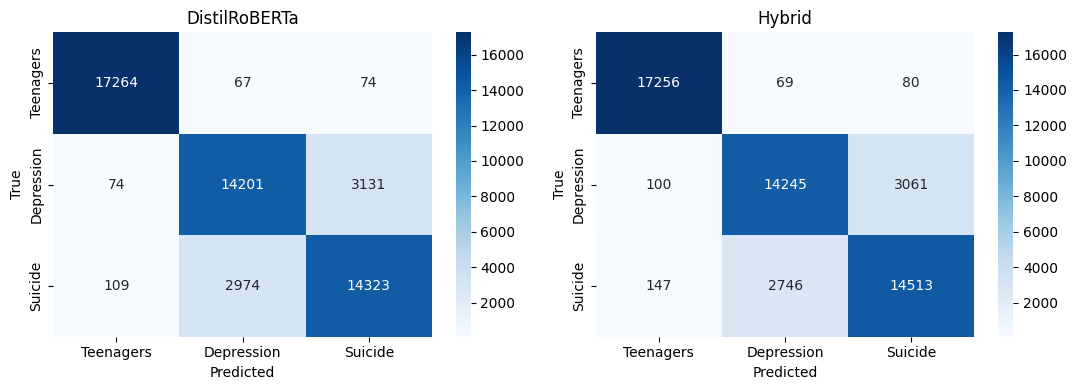

In [11]:
# 4c. Confusion matrices and per-class precision/recall (hybrid vs DistilRoBERTa, seed 42)
import seaborn as sns, matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11,4))
for k,(lab,p) in enumerate((("DistilRoBERTa", rb42), ("Hybrid", hy42))):
    cm = confusion_matrix(y_test, p.argmax(1)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[k]); ax[k].set_title(lab); ax[k].set_xlabel("Predicted"); ax[k].set_ylabel("True")
    pr, rc, f1, sup = precision_recall_fscore_support(y_test, p.argmax(1), labels=[0,1,2]); print(lab); print(pd.DataFrame(dict(precision=pr, recall=rc, f1=f1, support=sup), index=names).round(4))
    print("  Suicide missed -> Depression:", cm[2,1], "| -> General:", cm[2,0], "| Depression/General flagged as Suicide:", cm[0,2]+cm[1,2], "\n")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=200)

In [12]:
# 4d. Controls: is the gain from lexical-contextual complementarity, or from averaging ANY two models?
have = lambda t: os.path.exists(f"{OUT}/probs_{t}_test.npy")
ctrl = {"DistilRoBERTa s42 (alone)": (P(main,"val"), rb42)}
def avg(tags, split): return np.mean([P(t,split) for t in tags], axis=0)
if have("distilroberta_s43_e1"): ctrl["DistilRoBERTa s42+s43 (equal avg)"] = (avg([main,"distilroberta_s43_e1"],"val"), avg([main,"distilroberta_s43_e1"],"test"))
if have("distilbert_s42_e1"):   ctrl["DistilRoBERTa+DistilBERT (equal avg)"] = (avg([main,"distilbert_s42_e1"],"val"), avg([main,"distilbert_s42_e1"],"test"))
if all(have(f"distilroberta_s{s}_e1") for s in (42,43,44)):
    r3 = ["distilroberta_s42_e1","distilroberta_s43_e1","distilroberta_s44_e1"]; ctrl["DistilRoBERTa 3-seed avg"] = (avg(r3,"val"), avg(r3,"test"))
rows = []
for lab,(pv,pt) in ctrl.items(): rows.append(dict(model=lab, **summarize(y_test, pt), **recall_at_fpr(y_test, pt), **{"mcnemar_p_vs_hybrid": mcnemar_p(y_test, pt, hy42)["p"]}))
rows.append(dict(model=f"Hybrid LGBM+DistilRoBERTa (alpha={a42})", **summarize(y_test, hy42), **recall_at_fpr(y_test, hy42)))
for lab,(pv,pt) in list(ctrl.items())[1:]:            # add LightGBM on top of each stronger neural ensemble (val-selected alpha)
    a = pick_alpha(pv, lex_v, y_val); p = a*pt + (1-a)*lex_t; rows.append(dict(model=f"{lab} + LightGBM (alpha={a})", **summarize(y_test, p), **recall_at_fpr(y_test, p)))
# stacking baseline: logistic-regression meta-learner fitted on VALIDATION probabilities only
meta = LogisticRegression(max_iter=2000).fit(np.hstack([P(main,"val"), lex_v]), y_val); ps = meta.predict_proba(np.hstack([rb42, lex_t]))
rows.append(dict(model="Stacking LR (LGBM+DistilRoBERTa)", **summarize(y_test, ps), **recall_at_fpr(y_test, ps), **{"mcnemar_p_vs_hybrid": mcnemar_p(y_test, ps, hy42)["p"]}))
ctrl_df = pd.DataFrame(rows); print(ctrl_df.round(4).to_string(index=False)); ctrl_df.to_csv(f"{OUT}/controls.csv", index=False)

                                                       model    acc    f1w  prec_w  rec_suicide  prec_suicide  auc_suicide  recall@FPR1%  recall@FPR2%  recall@FPR5%  recall@FPR10%  mcnemar_p_vs_hybrid
                                   DistilRoBERTa s42 (alone) 0.8769 0.8768  0.8768       0.8229        0.8171       0.9501        0.4092        0.5217        0.6990         0.8380               0.0000
                           DistilRoBERTa s42+s43 (equal avg) 0.8786 0.8785  0.8784       0.8233        0.8214       0.9509        0.4177        0.5298        0.7006         0.8434               0.0016
                        DistilRoBERTa+DistilBERT (equal avg) 0.8776 0.8775  0.8775       0.8282        0.8177       0.9497        0.4147        0.5166        0.6989         0.8413               0.0000
                                    DistilRoBERTa 3-seed avg 0.8791 0.8789  0.8788       0.8192        0.8250       0.9511        0.4120        0.5334        0.7035         0.8445               0.

## 5. Near-duplicate check (test vs train+val) and re-evaluation without them

In [13]:
from datasketch import MinHash, MinHashLSH
def shingle_set(t, k=5, cap=300):
    w = re.findall(r"[a-z0-9']+", str(t).lower())[:cap]; return {" ".join(w[i:i+k]) for i in range(max(1, len(w)-k+1))}
def minhash(t, num_perm=64):
    m = MinHash(num_perm=num_perm); m.update_batch([s.encode() for s in shingle_set(t)]); return m
THRESH = 0.8
lsh = MinHashLSH(threshold=THRESH, num_perm=64)
t0 = time.time()
for i, t in enumerate(pd.concat([train_df.text, val_df.text], ignore_index=True)): lsh.insert(str(i), minhash(t))
print(f"indexed train+val in {(time.time()-t0)/60:.1f} min")
near = np.array([len(lsh.query(minhash(t))) > 0 for t in test_df.text])
print(f"test posts with a near-duplicate (Jaccard>={THRESH}) in train/val: {near.sum()} ({near.mean()*100:.2f}%)")
np.save(f"{OUT}/test_near_dup_mask.npy", near)
for lab, p in (("DistilRoBERTa", rb42), ("Hybrid", hy42)):
    print(lab, "| all test:", {k: round(v,4) for k,v in summarize(y_test, p).items() if k in ("acc","rec_suicide")},
          "| near-dups removed:", {k: round(v,4) for k,v in summarize(y_test[~near], p[~near]).items() if k in ("acc","rec_suicide")})
print("McNemar (near-dups removed):", mcnemar_p(y_test[~near], rb42[~near], hy42[~near]))
print("Paired bootstrap (near-dups removed):", paired_bootstrap(y_test[~near], rb42[~near], hy42[~near]))

indexed train+val in 3.4 min
test posts with a near-duplicate (Jaccard>=0.8) in train/val: 260 (0.50%)
DistilRoBERTa | all test: {'acc': 0.8769, 'rec_suicide': np.float64(0.8229)} | near-dups removed: {'acc': 0.877, 'rec_suicide': np.float64(0.8233)}
Hybrid | all test: {'acc': 0.8812, 'rec_suicide': np.float64(0.8338)} | near-dups removed: {'acc': 0.8814, 'rec_suicide': np.float64(0.8343)}
McNemar (near-dups removed): {'only_A_correct': 751, 'only_B_correct': 981, 'p': 3.744031947324307e-08}
Paired bootstrap (near-dups removed): {'acc_diff': (0.004402794618626944, 0.0027907692899897807, 0.006043940181303756), 'suicide_recall_diff': (0.010972853168626916, 0.007622540669937383, 0.014279128631950933)}


## 6. Source checks (label = source confound)

In [15]:
if "source" in test_df.columns:
    print("Test posts by source x label:\n", pd.crosstab(test_df.source, test_df.label))
    for s in test_df.source.unique():
        m = (test_df.source == s).values
        if m.sum():
            print(s, "n =", m.sum(), "| DistilRoBERTa acc", round(accuracy_score(y_test[m], rb42[m].argmax(1)), 4),
                  "| Hybrid acc", round(accuracy_score(y_test[m], hy42[m].argmax(1)), 4))

    # Can a text classifier tell which FILE a General/Teenagers post came from?
    tm, em = (train_df.label == 0).values, (test_df.label == 0).values
    srcs = train_df.source[tm].unique().tolist()
    if len(srcs) < 2:
        print(f"\nSource-predictability test skipped: all General/Teenagers train posts come from one file: {srcs}.")
        print("Train posts by source x label:\n", pd.crosstab(train_df.source, train_df.label))
    else:
        from sklearn.linear_model import SGDClassifier
        clf = SGDClassifier(loss="log_loss", random_state=42).fit(X_train_vec[tm], train_df.source[tm])
        print("Source predictable among General posts: acc =", round(clf.score(X_test_vec[em], test_df.source[em]), 4))
else:
    print("No source column (you loaded pre-made splits). Rebuild from raw CSVs (SPLIT_DIR=None) to get per-source results.")

Test posts by source x label:
 label                         0      1      2
source                                       
v13_SuicideAndDepression      0  17406      0
v14_Suicide_Detection     17405      0  17406
v13_SuicideAndDepression n = 17406 | DistilRoBERTa acc 0.8159 | Hybrid acc 0.8184
v14_Suicide_Detection n = 34811 | DistilRoBERTa acc 0.9074 | Hybrid acc 0.9126

Source-predictability test skipped: all General/Teenagers train posts come from one file: ['v14_Suicide_Detection'].
Train posts by source x label:
 label                         0      1      2
source                                       
v13_SuicideAndDepression      0  81224      0
v14_Suicide_Detection     81226      0  81226


In [16]:
t14, t13 = set(v14.text.dropna()), set(v13.text.dropna())
both = len(t14 & t13)
print(f"v14 unique texts: {len(t14):,} | v13 unique texts: {len(t13):,} | in both files: {both:,}")
print(f"Share of v14 also in v13: {both/len(t14)*100:.1f}% | share of v13 also in v14: {both/len(t13)*100:.1f}%")
print("Union (what the paper calls the corpus):", len(t14 | t13))

v14 unique texts: 232,074 | v13 unique texts: 348,123 | in both files: 232,074
Share of v14 also in v13: 100.0% | share of v13 also in v14: 66.7%
Union (what the paper calls the corpus): 348123
